In [1]:
# FactoryMind evaluation setup

import torch
import pandas as pd
import numpy as np

from pathlib import Path

device = torch.device("cpu")

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "DS-MVTec"
STANDARD_PATH = BASE_DIR / "models" / "standard_multimodal.pth"
RELIABILITY_PATH = BASE_DIR / "models" / "reliability_aware_multimodal.pth"

print("Device:", device)
print("Dataset:", DATA_DIR.exists())
print("Standard checkpoint:", STANDARD_PATH.exists())
print("Reliability checkpoint:", RELIABILITY_PATH.exists())

Device: cpu
Dataset: True
Standard checkpoint: True
Reliability checkpoint: True


In [5]:
# Recreate the leakage-safe test split

from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit

raw_dataset = load_dataset("jiang-cc/MMAD", split="train")

rows = []

for i in range(len(raw_dataset)):
    row = raw_dataset[i]
    if str(row["query_image"]).startswith("DS-MVTec/"):
        rows.append(row)

df = pd.DataFrame(rows)

df["local_query_path"] = df["query_image"].apply(
    lambda x: str(DATA_DIR.parent / x)
)

df["label"] = df["answer"].map({
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3
})

df_model = df[
    ["query_image", "question", "options",
     "answer", "local_query_path", "label"]
].reset_index(drop=True)

gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(
        df_model,
        y=df_model["label"],
        groups=df_model["local_query_path"]
    )
)

temp_df = df_model.iloc[temp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        y=temp_df["label"],
        groups=temp_df["local_query_path"]
    )
)

test_df = temp_df.iloc[test_idx].reset_index(drop=True)

# Check test image availability

# Check test image availability

print("Test questions:", len(test_df))
print("Test unique images:", test_df["local_query_path"].nunique())
print(
    "Missing images:",
    test_df["local_query_path"].apply(lambda x: not Path(x).exists()).sum()
)

Test questions: 1251
Test unique images: 254
Missing images: 0


In [7]:
# Recreate exact trained architectures and load checkpoints

import torch
import torch.nn as nn
from torchvision import models
from transformers import AutoModel

device = torch.device("cpu")


class StandardMultimodalModel(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        resnet = models.resnet18(weights=None)

        self.image_encoder = nn.Sequential(
            *list(resnet.children())[:-1]
        )

        for param in self.image_encoder.parameters():
            param.requires_grad = False

        self.text_encoder = AutoModel.from_pretrained(
            "distilbert-base-uncased"
        )

        self.classifier = nn.Sequential(
            nn.Linear(512 + 768, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, image, input_ids, attention_mask):

        image_features = self.image_encoder(image).flatten(1)

        text_outputs = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        text_features = text_outputs.last_hidden_state[:, 0, :]

        fused_features = torch.cat(
            [image_features, text_features],
            dim=1
        )

        return self.classifier(fused_features)


class ReliabilityAwareMultimodalModel(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        resnet = models.resnet18(weights=None)

        self.image_encoder = nn.Sequential(
            *list(resnet.children())[:-1]
        )

        for param in self.image_encoder.parameters():
            param.requires_grad = False

        self.text_encoder = AutoModel.from_pretrained(
            "distilbert-base-uncased"
        )

        self.image_reliability = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        self.text_reliability = nn.Sequential(
            nn.Linear(768, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        self.classifier = nn.Sequential(
            nn.Linear(512 + 768, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, image, input_ids, attention_mask):

        image_features = self.image_encoder(image).flatten(1)

        text_outputs = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        text_features = text_outputs.last_hidden_state[:, 0, :]

        image_weight = self.image_reliability(image_features)
        text_weight = self.text_reliability(text_features)

        weight_sum = image_weight + text_weight + 1e-8

        image_weight = image_weight / weight_sum
        text_weight = text_weight / weight_sum

        weighted_image = image_features * image_weight
        weighted_text = text_features * text_weight

        fused_features = torch.cat(
            [weighted_image, weighted_text],
            dim=1
        )

        logits = self.classifier(fused_features)

        weights = torch.cat(
            [image_weight, text_weight],
            dim=1
        )

        return logits, weights


loaded_standard_model = StandardMultimodalModel().to(device)
loaded_reliability_model = ReliabilityAwareMultimodalModel().to(device)

loaded_standard_model.load_state_dict(
    torch.load(
        STANDARD_PATH,
        map_location=device,
        weights_only=True
    )
)

loaded_reliability_model.load_state_dict(
    torch.load(
        RELIABILITY_PATH,
        map_location=device,
        weights_only=True
    )
)

loaded_standard_model.eval()
loaded_reliability_model.eval()

print("Standard Multimodal Model loaded.")
print("Reliability-Aware Multimodal Model loaded.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Standard Multimodal Model loaded.
Reliability-Aware Multimodal Model loaded.


In [8]:
# Build test DataLoader

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from transformers import AutoTokenizer

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)


class FactoryMindTestDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["local_query_path"]
        ).convert("RGB")

        image = image_transform(image)

        text = (
            "Question: " +
            str(row["question"]) +
            "\nOptions: " +
            str(row["options"])
        )

        encoding = tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=256,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                row["label"],
                dtype=torch.long
            )
        }


test_dataset = FactoryMindTestDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Test DataLoader ready:", len(test_dataset), "samples")

Test DataLoader ready: 1251 samples


In [12]:
# Define robustness evaluation

from sklearn.metrics import accuracy_score, f1_score

def evaluate_condition(
    standard_model,
    reliability_model,
    condition="normal"
):
    standard_preds = []
    reliability_preds = []
    true_labels = []
    reliability_weights = []

    with torch.inference_mode():

        for batch in test_loader:

            images = batch["image"].to(device)
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            # Apply the selected perturbation
            if condition == "missing_image":
                images = torch.zeros_like(images)

            elif condition == "corrupted_image":
                noise = torch.randn_like(images) * 0.5
                images = torch.clamp(images + noise, -3, 3)

            elif condition == "missing_text":
                attention_mask = torch.zeros_like(attention_mask)

            # Standard multimodal
            standard_logits = standard_model(
                images,
                input_ids,
                attention_mask
            )

            # Reliability-aware multimodal
            reliability_logits, weights = reliability_model(
                images,
                input_ids,
                attention_mask
            )

            standard_preds.extend(
                torch.argmax(standard_logits, dim=1).cpu().numpy()
            )

            reliability_preds.extend(
                torch.argmax(reliability_logits, dim=1).cpu().numpy()
            )

            true_labels.extend(labels.cpu().numpy())
            reliability_weights.append(weights.cpu())

    standard_result = {
        "accuracy": accuracy_score(true_labels, standard_preds),
        "macro_f1": f1_score(
            true_labels, standard_preds, average="macro"
        ),
        "weighted_f1": f1_score(
            true_labels, standard_preds, average="weighted"
        )
    }

    reliability_result = {
        "accuracy": accuracy_score(true_labels, reliability_preds),
        "macro_f1": f1_score(
            true_labels, reliability_preds, average="macro"
        ),
        "weighted_f1": f1_score(
            true_labels, reliability_preds, average="weighted"
        )
    }

    weights = torch.cat(reliability_weights, dim=0)

    return standard_result, reliability_result, weights

print("Robustness evaluator ready.")


Robustness evaluator ready.


In [13]:
# Evaluate missing-image condition

standard_missing_img, reliability_missing_img, weights_missing_img = evaluate_condition(
    loaded_standard_model,
    loaded_reliability_model,
    condition="missing_image"
)

missing_image_results = pd.DataFrame([
    {
        "model": "Standard Multimodal",
        **standard_missing_img
    },
    {
        "model": "Reliability-Aware",
        **reliability_missing_img
    }
])

display(missing_image_results.round(4))

,model,accuracy,macro_f1,weighted_f1
0,Standard Multimodal,0.7082,0.7093,0.7077
1,Reliability-Aware,0.7658,0.7688,0.7654


In [14]:
# Evaluate missing-text condition

standard_missing_text, reliability_missing_text, weights_missing_text = evaluate_condition(
    loaded_standard_model,
    loaded_reliability_model,
    condition="missing_text"
)

missing_text_results = pd.DataFrame([
    {
        "model": "Standard Multimodal",
        **standard_missing_text
    },
    {
        "model": "Reliability-Aware",
        **reliability_missing_text
    }
])

display(missing_text_results.round(4))

,model,accuracy,macro_f1,weighted_f1
0,Standard Multimodal,0.3141,0.1660,0.2083
1,Reliability-Aware,0.2022,0.0841,0.0680


In [15]:
# Evaluate corrupted-image condition

standard_corrupt, reliability_corrupt, weights_corrupt = evaluate_condition(
    loaded_standard_model,
    loaded_reliability_model,
    condition="corrupted_image"
)

corrupted_image_results = pd.DataFrame([
    {
        "model": "Standard Multimodal",
        **standard_corrupt
    },
    {
        "model": "Reliability-Aware",
        **reliability_corrupt
    }
])

display(corrupted_image_results.round(4))

,model,accuracy,macro_f1,weighted_f1
0,Standard Multimodal,0.7082,0.7081,0.7079
1,Reliability-Aware,0.7658,0.7683,0.7655


In [16]:
# Evaluate contradictory-text condition

def evaluate_contradictory_text():
    standard_preds = []
    reliability_preds = []
    true_labels = []
    reliability_weights = []

    with torch.inference_mode():

        for batch in test_loader:

            images = batch["image"].to(device)
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            # Decode original text and append contradictory inspection report
            texts = tokenizer.batch_decode(
                input_ids,
                skip_special_tokens=True
            )

            contradictory_texts = [
                text +
                "\nContradictory inspection report: "
                "The object is normal and has no visible defect."
                for text in texts
            ]

            encoded = tokenizer(
                contradictory_texts,
                padding="max_length",
                truncation=True,
                max_length=256,
                return_tensors="pt"
            )

            contradictory_ids = encoded["input_ids"].to(device)
            contradictory_mask = encoded["attention_mask"].to(device)

            # Standard multimodal
            standard_logits = loaded_standard_model(
                images,
                contradictory_ids,
                contradictory_mask
            )

            # Reliability-aware multimodal
            reliability_logits, weights = loaded_reliability_model(
                images,
                contradictory_ids,
                contradictory_mask
            )

            standard_preds.extend(
                torch.argmax(standard_logits, dim=1).cpu().numpy()
            )

            reliability_preds.extend(
                torch.argmax(reliability_logits, dim=1).cpu().numpy()
            )

            true_labels.extend(labels.cpu().numpy())
            reliability_weights.append(weights.cpu())

    standard_result = {
        "accuracy": accuracy_score(true_labels, standard_preds),
        "macro_f1": f1_score(
            true_labels, standard_preds, average="macro"
        ),
        "weighted_f1": f1_score(
            true_labels, standard_preds, average="weighted"
        )
    }

    reliability_result = {
        "accuracy": accuracy_score(true_labels, reliability_preds),
        "macro_f1": f1_score(
            true_labels, reliability_preds, average="macro"
        ),
        "weighted_f1": f1_score(
            true_labels, reliability_preds, average="weighted"
        )
    }

    weights = torch.cat(reliability_weights, dim=0)

    return standard_result, reliability_result, weights

In [17]:
# Run contradictory-text evaluation

standard_contradictory, reliability_contradictory, weights_contradictory = evaluate_contradictory_text()

contradictory_text_results = pd.DataFrame([
    {
        "model": "Standard Multimodal",
        **standard_contradictory
    },
    {
        "model": "Reliability-Aware",
        **reliability_contradictory
    }
])

display(contradictory_text_results.round(4))

,model,accuracy,macro_f1,weighted_f1
0,Standard Multimodal,0.2638,0.2429,0.2137
1,Reliability-Aware,0.2310,0.2292,0.2404


In [18]:
# Build final robustness comparison

results = pd.DataFrame([
    ["Normal", "Standard Multimodal", 0.7018, 0.7014, 0.7010],
    ["Normal", "Reliability-Aware", 0.7658, 0.7683, 0.7655],

    ["Missing Image", "Standard Multimodal",
     standard_missing_img["accuracy"],
     standard_missing_img["macro_f1"],
     standard_missing_img["weighted_f1"]],

    ["Missing Image", "Reliability-Aware",
     reliability_missing_img["accuracy"],
     reliability_missing_img["macro_f1"],
     reliability_missing_img["weighted_f1"]],

    ["Missing Text", "Standard Multimodal",
     standard_missing_text["accuracy"],
     standard_missing_text["macro_f1"],
     standard_missing_text["weighted_f1"]],

    ["Missing Text", "Reliability-Aware",
     reliability_missing_text["accuracy"],
     reliability_missing_text["macro_f1"],
     reliability_missing_text["weighted_f1"]],

    ["Corrupted Image", "Standard Multimodal",
     standard_corrupt["accuracy"],
     standard_corrupt["macro_f1"],
     standard_corrupt["weighted_f1"]],

    ["Corrupted Image", "Reliability-Aware",
     reliability_corrupt["accuracy"],
     reliability_corrupt["macro_f1"],
     reliability_corrupt["weighted_f1"]],

    ["Contradictory Text", "Standard Multimodal",
     standard_contradictory["accuracy"],
     standard_contradictory["macro_f1"],
     standard_contradictory["weighted_f1"]],

    ["Contradictory Text", "Reliability-Aware",
     reliability_contradictory["accuracy"],
     reliability_contradictory["macro_f1"],
     reliability_contradictory["weighted_f1"]]
], columns=["condition", "model", "accuracy", "macro_f1", "weighted_f1"])

display(results.round(4))

,condition,model,accuracy,macro_f1,weighted_f1
0,Normal,Standard Multimodal,0.7018,0.7014,0.7010
1,Normal,Reliability-Aware,0.7658,0.7683,0.7655
2,Missing Image,Standard Multimodal,0.7082,0.7093,0.7077
3,Missing Image,Reliability-Aware,0.7658,0.7688,0.7654
4,Missing Text,Standard Multimodal,0.3141,0.1660,0.2083
5,Missing Text,Reliability-Aware,0.2022,0.0841,0.0680
6,Corrupted Image,Standard Multimodal,0.7082,0.7081,0.7079
7,Corrupted Image,Reliability-Aware,0.7658,0.7683,0.7655
8,Contradictory Text,Standard Multimodal,0.2638,0.2429,0.2137
9,Contradictory Text,Reliability-Aware,0.2310,0.2292,0.2404


In [19]:
# Analyze modality reliability weights

weight_results = pd.DataFrame([
    {
        "condition": "Missing Image",
        "image_weight": weights_missing_img[:, 0].mean().item(),
        "text_weight": weights_missing_img[:, 1].mean().item()
    },
    {
        "condition": "Missing Text",
        "image_weight": weights_missing_text[:, 0].mean().item(),
        "text_weight": weights_missing_text[:, 1].mean().item()
    },
    {
        "condition": "Corrupted Image",
        "image_weight": weights_corrupt[:, 0].mean().item(),
        "text_weight": weights_corrupt[:, 1].mean().item()
    },
    {
        "condition": "Contradictory Text",
        "image_weight": weights_contradictory[:, 0].mean().item(),
        "text_weight": weights_contradictory[:, 1].mean().item()
    }
])

display(weight_results.round(4))

,condition,image_weight,text_weight
0,Missing Image,0.0783,0.9217
1,Missing Text,0.0203,0.9797
2,Corrupted Image,0.0109,0.9891
3,Contradictory Text,0.0122,0.9878


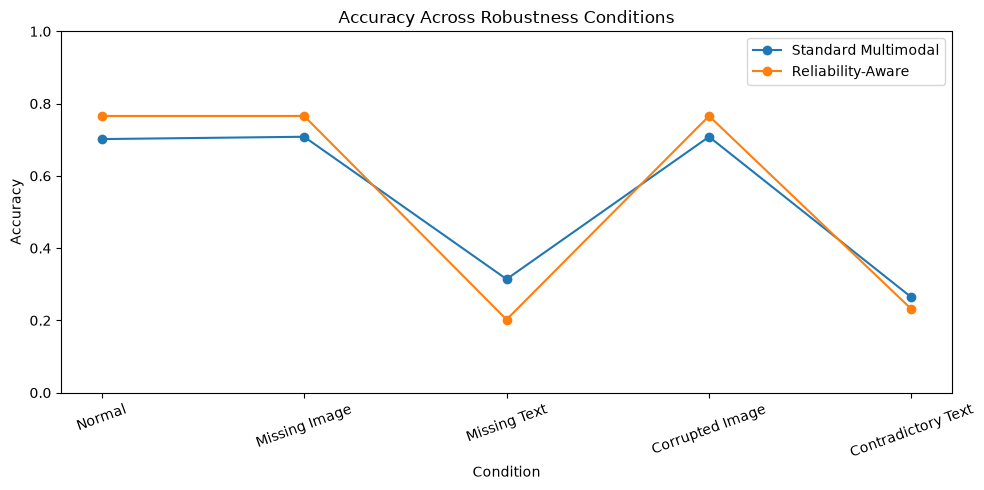

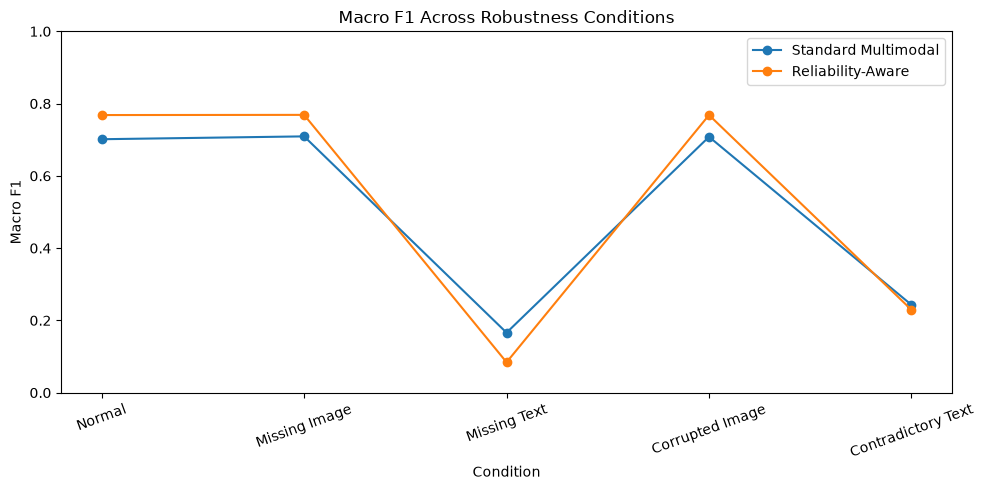

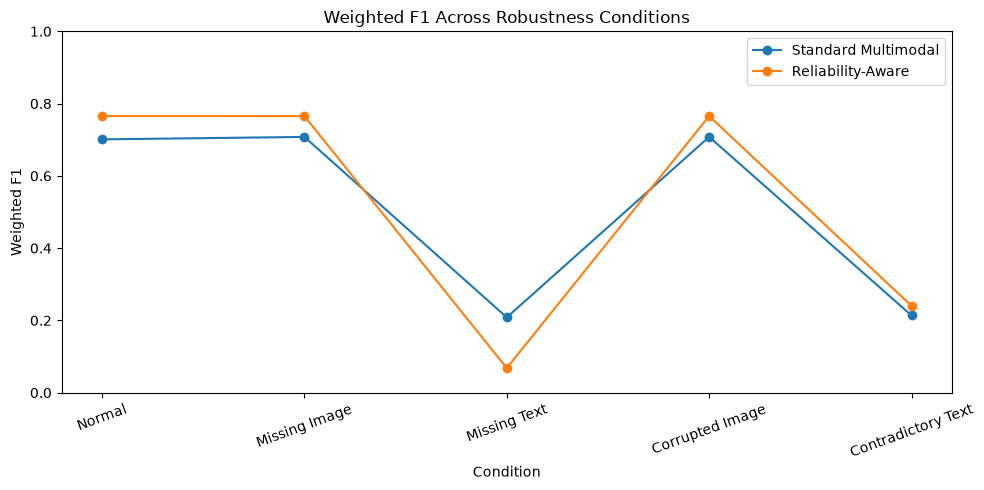

In [20]:
# Plot final robustness comparison

import matplotlib.pyplot as plt

plot_data = results.copy()

for metric in ["accuracy", "macro_f1", "weighted_f1"]:
    plt.figure(figsize=(10, 5))

    for model in plot_data["model"].unique():
        subset = plot_data[plot_data["model"] == model]
        plt.plot(
            subset["condition"],
            subset[metric],
            marker="o",
            label=model
        )

    plt.title(f"{metric.replace('_', ' ').title()} Across Robustness Conditions")
    plt.xlabel("Condition")
    plt.ylabel(metric.replace("_", " ").title())
    plt.xticks(rotation=20)
    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [21]:
# Calculate robustness performance changes

baseline = results[results["condition"] == "Normal"].set_index("model")

robustness_analysis = results[results["condition"] != "Normal"].copy()

robustness_analysis["accuracy_change"] = robustness_analysis.apply(
    lambda row: row["accuracy"] - baseline.loc[row["model"], "accuracy"],
    axis=1
)

robustness_analysis["macro_f1_change"] = robustness_analysis.apply(
    lambda row: row["macro_f1"] - baseline.loc[row["model"], "macro_f1"],
    axis=1
)

robustness_analysis["weighted_f1_change"] = robustness_analysis.apply(
    lambda row: row["weighted_f1"] - baseline.loc[row["model"], "weighted_f1"],
    axis=1
)

display(
    robustness_analysis[
        [
            "condition",
            "model",
            "accuracy_change",
            "macro_f1_change",
            "weighted_f1_change"
        ]
    ].round(4)
)

,condition,model,accuracy_change,macro_f1_change,weighted_f1_change
2,Missing Image,Standard Multimodal,0.0064,0.0079,0.0067
3,Missing Image,Reliability-Aware,-0.0000,0.0005,-0.0001
4,Missing Text,Standard Multimodal,-0.3877,-0.5354,-0.4927
5,Missing Text,Reliability-Aware,-0.5636,-0.6842,-0.6975
6,Corrupted Image,Standard Multimodal,0.0064,0.0067,0.0069
7,Corrupted Image,Reliability-Aware,-0.0000,0.0000,-0.0000
8,Contradictory Text,Standard Multimodal,-0.4380,-0.4585,-0.4873
9,Contradictory Text,Reliability-Aware,-0.5348,-0.5391,-0.5251


In [22]:
# Generate sample predictions

label_names = {
    0: "A",
    1: "B",
    2: "C",
    3: "D"
}

prediction_rows = []

loaded_standard_model.eval()
loaded_reliability_model.eval()

with torch.inference_mode():

    for batch_idx, batch in enumerate(test_loader):

        if batch_idx >= 3:   # 3 batches × 8 = 24 samples
            break

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        standard_logits = loaded_standard_model(
            images,
            input_ids,
            attention_mask
        )

        reliability_logits, _ = loaded_reliability_model(
            images,
            input_ids,
            attention_mask
        )

        standard_preds = torch.argmax(
            standard_logits, dim=1
        )

        reliability_preds = torch.argmax(
            reliability_logits, dim=1
        )

        for i in range(len(labels)):

            row = test_df.iloc[
                batch_idx * 8 + i
            ]

            prediction_rows.append({
                "Question": str(row["question"])[:100],
                "Actual": label_names[labels[i].item()],
                "Standard Prediction": label_names[
                    standard_preds[i].item()
                ],
                "Reliability-Aware Prediction": label_names[
                    reliability_preds[i].item()
                ],
                "Standard Correct": (
                    standard_preds[i].item() == labels[i].item()
                ),
                "Reliability Correct": (
                    reliability_preds[i].item() == labels[i].item()
                )
            })

predictions_df = pd.DataFrame(prediction_rows)

display(predictions_df)

,Question,Actual,Standard Prediction,Reliability-Aware Prediction,Standard Correct,Reliability Correct
0,Is there any defect in the object?,A,A,A,True,True
1,There is a defect in the object. What is the t...,A,A,A,True,True
2,There is a defect in the object. Where is the ...,D,C,C,False,False
3,There is a defect in the object. What is the a...,A,A,A,True,True
4,There is a defect in the object. How does the ...,A,A,A,True,True
5,Is there any defect in the object?,B,B,B,True,True
6,There is a defect in the object. What is the t...,D,D,D,True,True
7,There is a defect in the object. Where is the ...,C,C,A,True,False
8,There is a defect in the object. What is the a...,D,D,C,True,False
9,There is a defect in the object. How does the ...,B,B,B,True,True


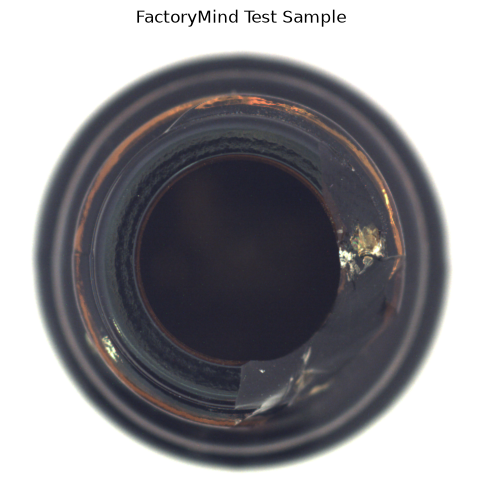

QUESTION:
Is there any defect in the object?

OPTIONS:
A: Yes.
B: No.

GROUND TRUTH: A
STANDARD MULTIMODAL: A (71.56%)
FACTORYMIND: A (65.79%)

RELIABILITY WEIGHTS:
Image: 0.29%
Text:  99.71%

CORRECTNESS:
Standard Multimodal: CORRECT
FactoryMind: CORRECT


In [23]:
# FactoryMind prediction demo on unseen test sample

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

# Select one unseen test sample
sample_idx = 0
row = test_df.iloc[sample_idx]

# Prepare image
image_pil = Image.open(row["local_query_path"]).convert("RGB")
image_tensor = image_transform(image_pil).unsqueeze(0).to(device)

# Prepare text
text = (
    "Question: " +
    str(row["question"]) +
    "\nOptions: " +
    str(row["options"])
)

encoding = tokenizer(
    text,
    padding="max_length",
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

input_ids = encoding["input_ids"].to(device)
attention_mask = encoding["attention_mask"].to(device)

# Run inference
loaded_standard_model.eval()
loaded_reliability_model.eval()

with torch.inference_mode():

    standard_logits = loaded_standard_model(
        image_tensor,
        input_ids,
        attention_mask
    )

    reliability_logits, reliability_weights = loaded_reliability_model(
        image_tensor,
        input_ids,
        attention_mask
    )

# Predictions
standard_probs = F.softmax(standard_logits, dim=1)[0]
reliability_probs = F.softmax(reliability_logits, dim=1)[0]

standard_pred = torch.argmax(standard_probs).item()
reliability_pred = torch.argmax(reliability_probs).item()
actual_label = int(row["label"])

label_names = {
    0: "A",
    1: "B",
    2: "C",
    3: "D"
}

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(image_pil)
plt.axis("off")
plt.title("FactoryMind Test Sample")
plt.show()

# Display prediction
print("QUESTION:")
print(row["question"])

print("\nOPTIONS:")
print(row["options"])

print("\n" + "=" * 50)
print("GROUND TRUTH:", label_names[actual_label])
print(
    "STANDARD MULTIMODAL:",
    label_names[standard_pred],
    f"({standard_probs[standard_pred].item():.2%})"
)
print(
    "FACTORYMIND:",
    label_names[reliability_pred],
    f"({reliability_probs[reliability_pred].item():.2%})"
)

print("\nRELIABILITY WEIGHTS:")
print(
    f"Image: {reliability_weights[0, 0].item():.2%}"
)
print(
    f"Text:  {reliability_weights[0, 1].item():.2%}"
)

print("\nCORRECTNESS:")
print(
    "Standard Multimodal:",
    "CORRECT" if standard_pred == actual_label else "WRONG"
)
print(
    "FactoryMind:",
    "CORRECT" if reliability_pred == actual_label else "WRONG"
)